In [30]:
###Official project no 2
# this is also linked to sustainability, reaching  net zero etc so MAKE SURE YOU WORD YOURSELF PORPERLY WHEN POSTING

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
import copy
import seaborn as sns
import tensorflow as tf
from sklearn.linear_model import LinearRegression

In [32]:

df = pd.read_csv("household_power_consumption.zip", sep = ';', na_values = '?', encoding = 'latin-1', low_memory = 'False')
# sep separates data from semicolons
# na_values plaes na for and questions marks in data
# the encoding justr allows special characters to be read properly

df.columns = ["date", "time", "global_active_power", "global_reactive_power", "voltage", "global_intensity", "sub_metering_1", "sub_metering_2", "sub_metering_3"]


df.head()

,date,time,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [33]:
###################

C:\Users\yas-s\AppData\Local\Temp\ipykernel_4980\4030327269.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


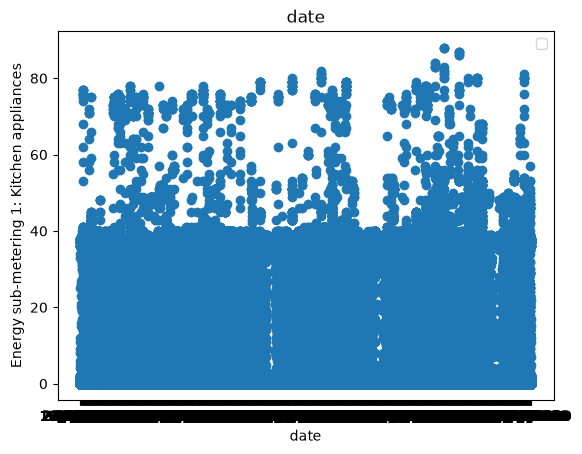

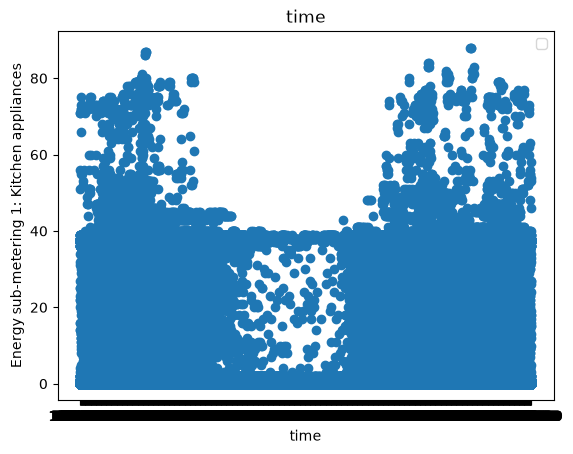

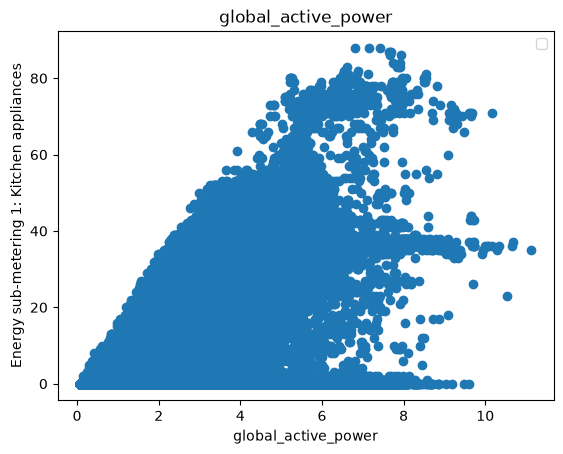

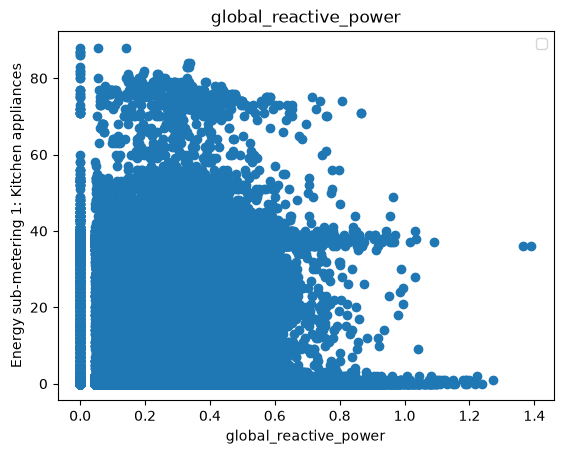

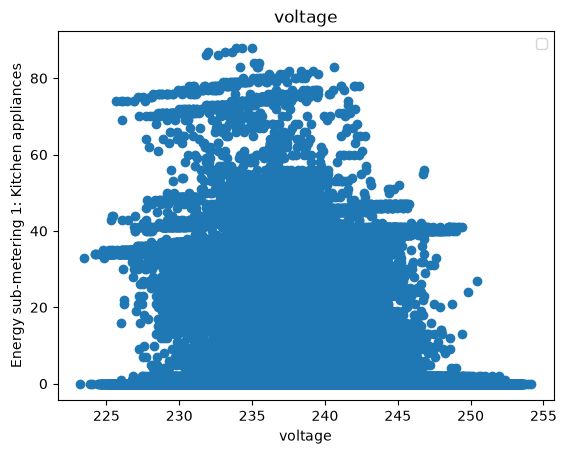

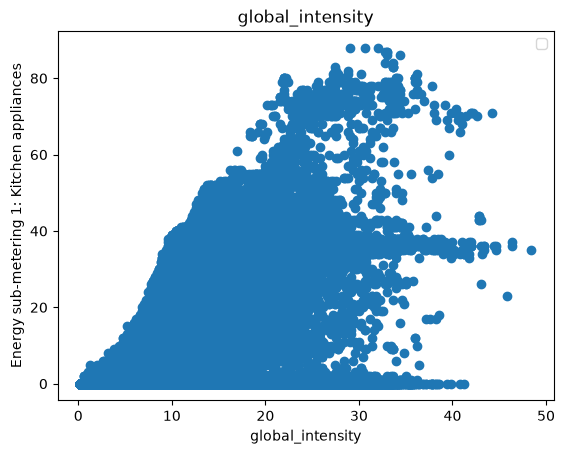

In [34]:
for label in df.columns[:-3]:
  plt.scatter(df[label], df["sub_metering_1"])
  plt.title(label)
  plt.ylabel("Energy sub-metering 1: Kitchen appliances")
  plt.xlabel(label)
  plt.legend()
  plt.show()
#helps correlation observations

In [35]:
df.corr(numeric_only=True)["sub_metering_1"].sort_values(ascending=False)

sub_metering_1           1.000000
global_intensity         0.489298
global_active_power      0.484401
global_reactive_power    0.123111
sub_metering_3           0.102571
sub_metering_2           0.054721
voltage                 -0.195976
Name: sub_metering_1, dtype: float64

C:\Users\yas-s\AppData\Local\Temp\ipykernel_4980\1460416123.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


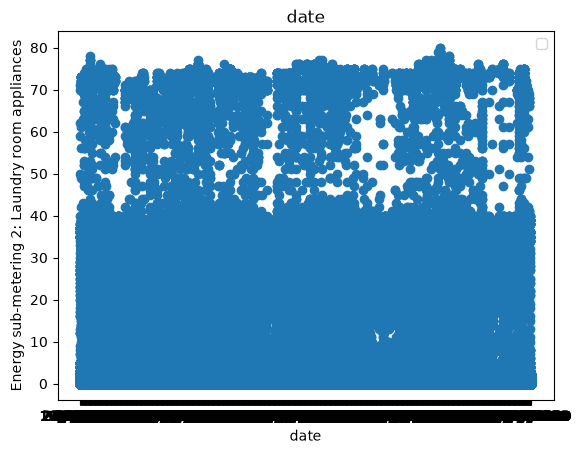

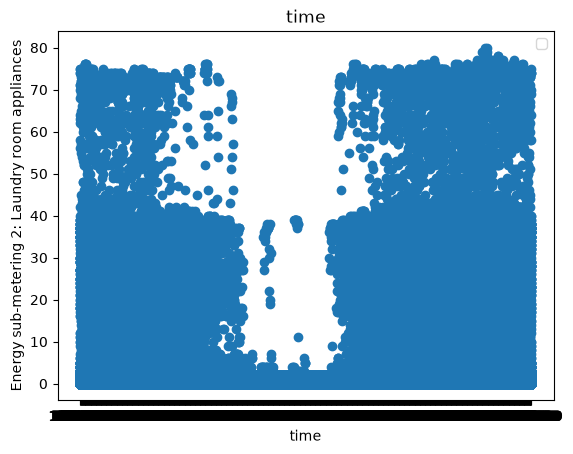

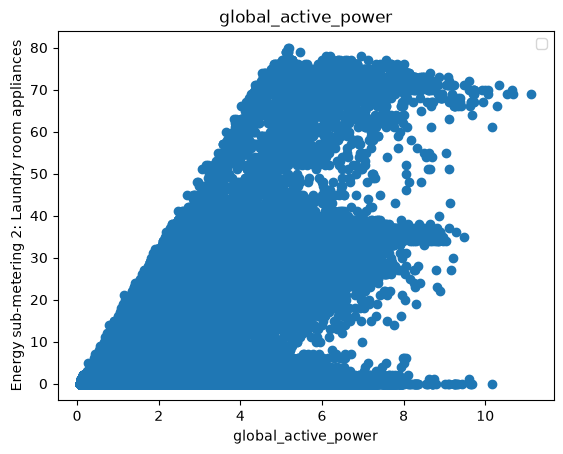

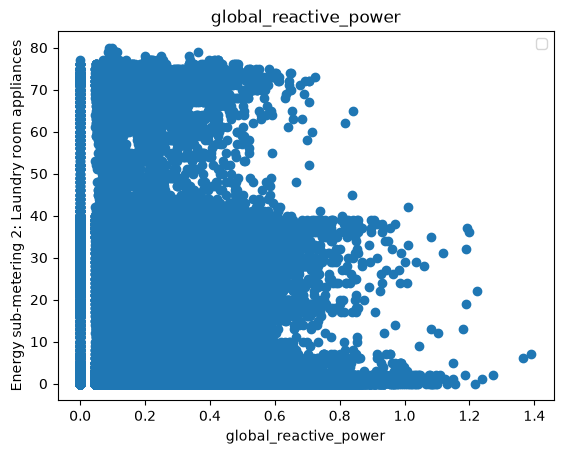

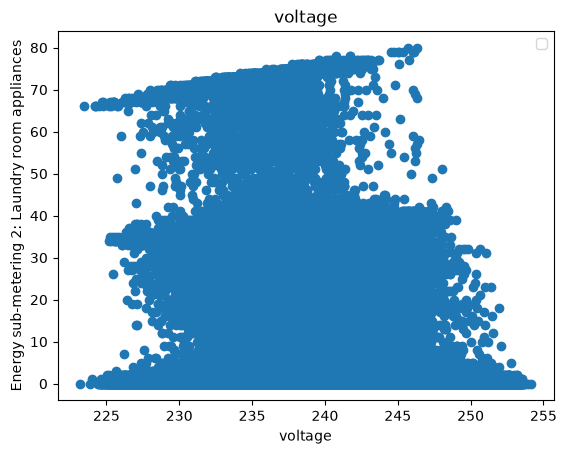

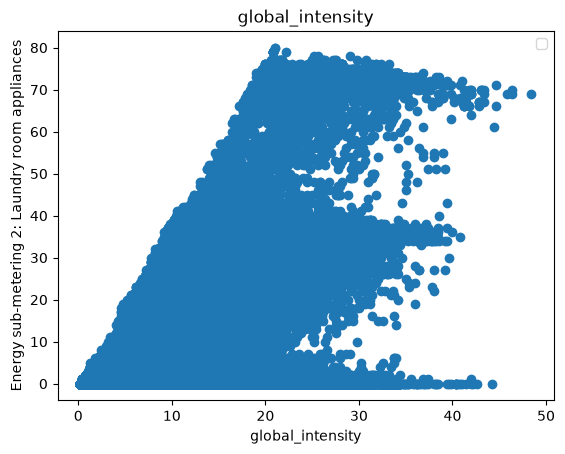

In [36]:
for label in df.columns[:-3]:
  plt.scatter(df[label], df["sub_metering_2"])
  plt.title(label)
  plt.ylabel("Energy sub-metering 2: Laundry room appliances")
  plt.xlabel(label)
  plt.legend()
  plt.show()
#helps correlation observations

In [37]:
df.corr(numeric_only=True)["sub_metering_2"].sort_values(ascending=False)

sub_metering_2           1.000000
global_intensity         0.440347
global_active_power      0.434569
global_reactive_power    0.139231
sub_metering_3           0.080872
sub_metering_1           0.054721
voltage                 -0.167405
Name: sub_metering_2, dtype: float64

C:\Users\yas-s\AppData\Local\Temp\ipykernel_4980\30351699.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


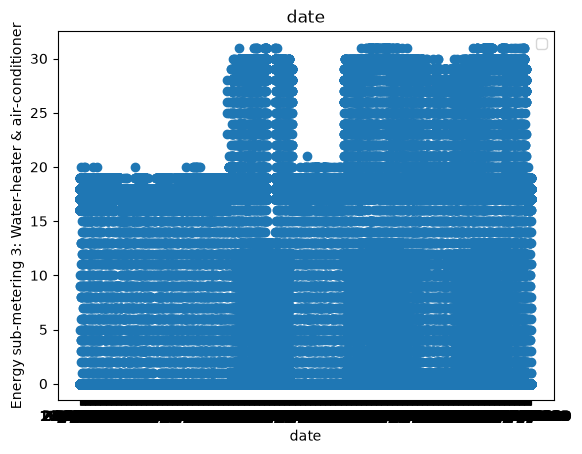

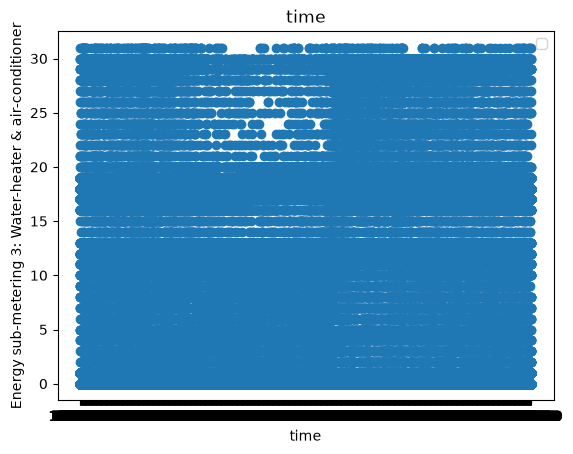

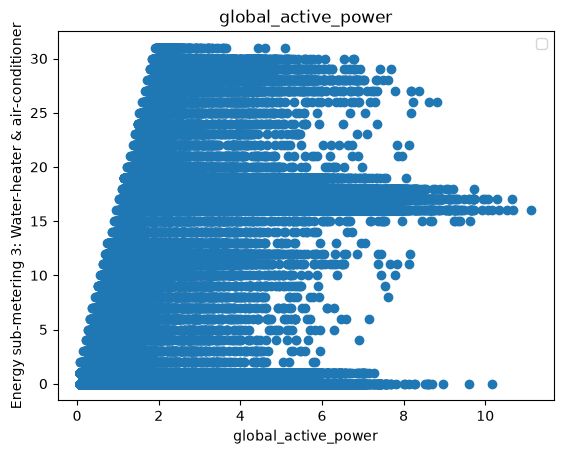

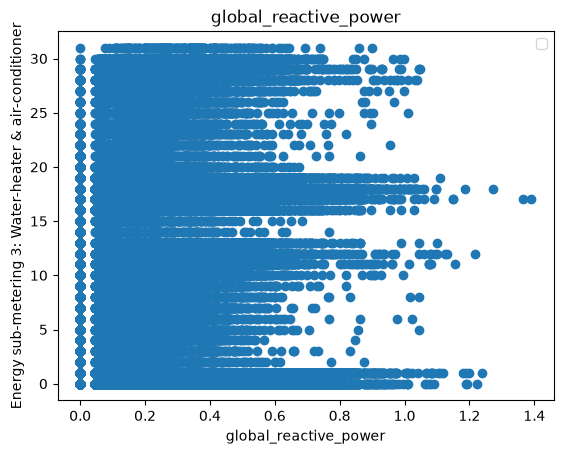

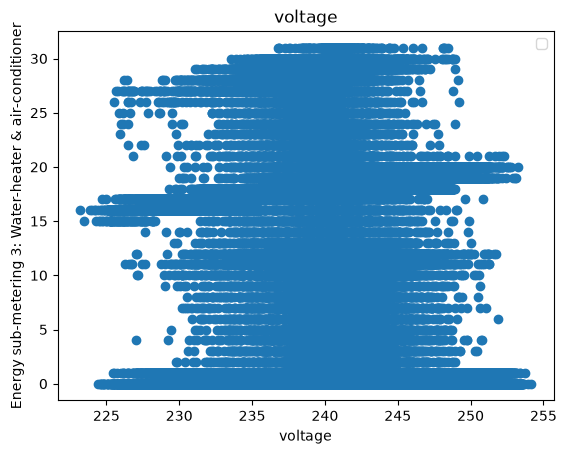

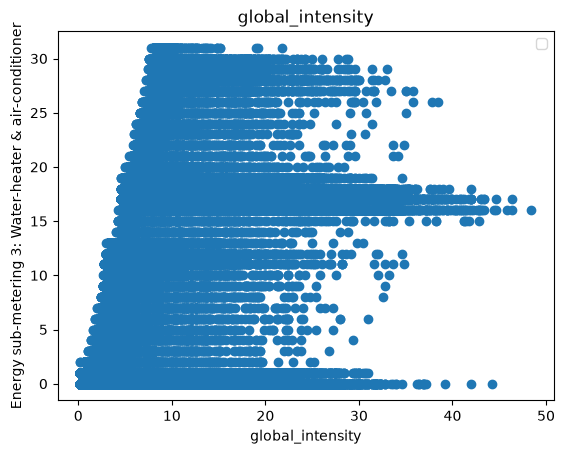

In [38]:
for label in df.columns[:-3]:
  plt.scatter(df[label], df["sub_metering_3"])
  plt.title(label)
  plt.ylabel("Energy sub-metering 3: Water-heater & air-conditioner")
  plt.xlabel(label)
  plt.legend()
  plt.show()
#helps correlation observations

In [39]:
df.corr(numeric_only=True)["sub_metering_3"].sort_values(ascending=False)

sub_metering_3           1.000000
global_active_power      0.638555
global_intensity         0.626543
sub_metering_1           0.102571
global_reactive_power    0.089617
sub_metering_2           0.080872
voltage                 -0.268172
Name: sub_metering_3, dtype: float64

In [40]:
#here, after observing correlations, instead of dropping features using personal judgement,
#the correlation coefficients of each feature is calculated and correlations that aere within range -0.3 to 0.3
#are disregarded.
# this makes the elimination process systematic and less prone to human bias

In [41]:
#now time to drop:

In [42]:
df = df.drop(["date", "time", "voltage", "global_reactive_power"], axis = 1)
df.head()

,global_active_power,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
0,4.216,18.4,0.0,1.0,17.0
1,5.360,23.0,0.0,1.0,16.0
2,5.374,23.0,0.0,2.0,17.0
3,5.388,23.0,0.0,1.0,17.0
4,3.666,15.8,0.0,1.0,17.0


In [43]:
df["total_meter_value"] = df["sub_metering_1"] + df["sub_metering_2"] + df["sub_metering_3"]
df.head()

,global_active_power,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3,total_meter_value
0,4.216,18.4,0.0,1.0,17.0,18.0
1,5.360,23.0,0.0,1.0,16.0,17.0
2,5.374,23.0,0.0,2.0,17.0,19.0
3,5.388,23.0,0.0,1.0,17.0,18.0
4,3.666,15.8,0.0,1.0,17.0,18.0


In [44]:
df = df.drop(["sub_metering_1", "sub_metering_2", "sub_metering_3"], axis = 1)
df.head()

,global_active_power,global_intensity,total_meter_value
0,4.216,18.4,18.0
1,5.360,23.0,17.0
2,5.374,23.0,19.0
3,5.388,23.0,18.0
4,3.666,15.8,18.0


In [45]:
#now that the irrelevant data is filtered out, we can comfortably start separating our training, validation and testing datasets

In [46]:
################################
################################
################################


In [47]:
print(df.isna().sum())
print(len(df))


global_active_power    25979
global_intensity       25979
total_meter_value      25979
dtype: int64
2075259


In [48]:
df = df.dropna()

In [49]:
print(df.isna().sum())
print(len(df))


global_active_power    0
global_intensity       0
total_meter_value      0
dtype: int64
2049280


In [50]:
train, val, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])

In [51]:
def get_xy(dataframe, y_label, x_labels = None):
  dataframe = copy.deepcopy(dataframe) #copying everything over
  if x_labels is None:
    X = dataframe[[c for c in dataframe.columns if c != y_label]].values
  else:
    if len(x_labels) == 1:
      X = dataframe[x_labels[0]].values.reshape(-1,1)
    else:
      X = dataframe[x_labels].values
  y = dataframe[y_label].values.reshape(-1,1)
  data = np.hstack((X,y))

  return data, X, y



In [52]:
####now to actually start coding

In [53]:
#rows with missing data were dropped as they only wokred to be 1.25% of total data

In [54]:
_, X_train_all, y_train_all = get_xy(train,"total_meter_value", x_labels = df.columns[:-1])
_, X_val_all, y_val_all = get_xy(val,"total_meter_value", x_labels = df.columns[:-1])
_, X_test_all, y_test_all = get_xy(test,"total_meter_value", x_labels = df.columns[:-1])

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [ ]:
all_reg = LinearRegression()
all_reg.fit(X_train_all, y_train_all)

LinearRegression()

In [ ]:
all_reg.score(X_test_all, y_test_all)

0.7178905967209809

In [ ]:
y_pred_lr = all_reg.predict(X_test_all)

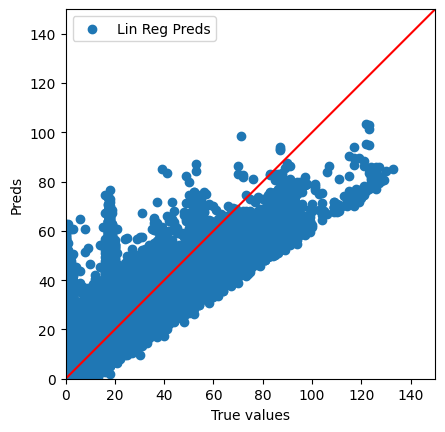

In [ ]:
ax = plt.axes(aspect = "equal")
plt.scatter(y_test_all, y_pred_lr, label = "Lin Reg Preds")
#plt.scatter(y_test_all, y_pred_nn, label = "NN Reg Preds")
plt.xlabel("True values")
plt.ylabel("Preds")
lims = [0,150]
plt.xlim(lims)
plt.ylim(lims)
plt.legend()
#_ = plt.plot(lims, lims, c= "red")
_ = plt.plot(lims, lims,  c= "red")

In [ ]:
######now to do nn model :((((((((((((((((((((( aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa

In [ ]:
all_normaliser = tf.keras.layers.Normalization(input_shape=(2,), axis = -1)
all_normaliser.adapt(X_train_all)

nn_model = tf.keras.Sequential([
    all_normaliser,
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(1)
])
nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss= 'mean_squared_error')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
history = nn_model.fit(
    X_train_all, y_train_all,
    validation_data = (X_val_all, y_val_all),
    verbose = 0, epochs = 20
)

In [ ]:
y_pred_nn = nn_model.predict(X_test_all)

12808/12808 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step


In [ ]:
def MSE(y_pred, y_real):
  return (np.square(y_pred - y_real)).mean()

In [ ]:
MSE(y_pred_lr, y_test_all)

np.float64(46.6282082234256)

In [ ]:
MSE(y_pred_nn, y_test_all)

np.float64(38.95956152242781)

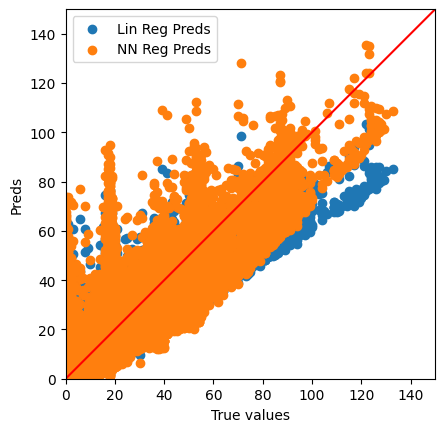

In [ ]:
ax = plt.axes(aspect = "equal")
plt.scatter(y_test_all, y_pred_lr, label = "Lin Reg Preds")
plt.scatter(y_test_all, y_pred_nn, label = "NN Reg Preds")
plt.xlabel("True values")
plt.ylabel("Preds")
lims = [0,150]
plt.xlim(lims)
plt.ylim(lims)
plt.legend()
_ = plt.plot(lims, lims, c= "red")